<a href="https://colab.research.google.com/github/20204385-stack/Thesis_2026-1/blob/main/Thesis_Preprocesing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#######################-Drive mounting-#########################
from google.colab import drive
# Mount to the standard base directory
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
######################-Folder targeting-###########################333
import os
import glob
import pandas as pd

# Define paths. We search for 'colab_test' recursively under Google Drive
base_drive_path = '/content/drive/MyDrive'
target_folder = None

for root, dirs, files in os.walk(base_drive_path):
    if 'colab_test' in dirs:
        target_folder = os.path.join(root, 'colab_test')
        break

if not target_folder:
    # Fallback to direct search if not found in subdirectories
    target_folder = os.path.join(base_drive_path, 'colab_test')

print(f"Target folder identified at: {target_folder}")

Target folder identified at: /content/drive/MyDrive/colab_test


In [ ]:
################################-Captures compiling-#################################3
import os
import glob
import pandas as pd

# Locate all .txt files
txt_files = sorted(glob.glob(os.path.join(target_folder, '*.txt')))
print(f"Found {len(txt_files)} text files to process in batches.")

output_path = os.path.join(target_folder, 'unified_captures.csv')

# Remove existing output file if it exists to start fresh
if os.path.exists(output_path):
    os.remove(output_path)

# We will process each file in chunks to minimize memory footprint
chunk_size = 50000
first_write = True

for file_path in txt_files:
    filename = os.path.basename(file_path)
    capture_id = os.path.splitext(filename)[0]
    print(f"Processing: {filename}...")

    try:
        # Read the file in chunks
        reader = pd.read_csv(file_path, sep=None, engine='python', chunksize=chunk_size)

        for chunk in reader:
            # Add the captureID column
            chunk['captureID'] = capture_id

            # Write chunk to CSV
            if first_write:
                chunk.to_csv(output_path, mode='w', index=False)
                first_write = False
            else:
                chunk.to_csv(output_path, mode='a', header=False, index=False)

        print(f"Finished processing {filename}.")
    except Exception as e:
        print(f"Error processing {filename}: {e}")

if os.path.exists(output_path):
    print(f"\nAll batches processed! Unified file saved to: {output_path}")
    # Display a preview of the saved file
    preview_df = pd.read_csv(output_path, nrows=5)
    display(preview_df)
else:
    print("No data was processed.")

Found 13 text files to process in batches.
Processing: capture20110810.binetflow.txt...
Finished processing capture20110810.binetflow.txt.
Processing: capture20110811.binetflow.txt...
Finished processing capture20110811.binetflow.txt.
Processing: capture20110812.binetflow.txt...
Finished processing capture20110812.binetflow.txt.
Processing: capture20110815-2.binetflow.txt...
Finished processing capture20110815-2.binetflow.txt.
Processing: capture20110815-3.binetflow.txt...
Finished processing capture20110815-3.binetflow.txt.
Processing: capture20110815.binetflow.txt...
Finished processing capture20110815.binetflow.txt.
Processing: capture20110816-2.binetflow.txt...
Finished processing capture20110816-2.binetflow.txt.
Processing: capture20110816-3.binetflow.txt...
Finished processing capture20110816-3.binetflow.txt.
Processing: capture20110816.binetflow.txt...
Finished processing capture20110816.binetflow.txt.
Processing: capture20110817.binetflow.txt...
Finished processing capture20110

,StartTime,Dur,Proto,SrcAddr,Sport,Dir,DstAddr,Dport,State,sTos,dTos,TotPkts,TotBytes,SrcBytes,Label,captureID
0,2011/08/10 09:46:53.047277,3550.182373,udp,212.50.71.179,39678,<->,147.32.84.229,13363,CON,0.0,0.0,12,875,413,flow=Background-UDP-Established,capture20110810.binetflow
1,2011/08/10 09:46:53.048843,0.000883,udp,84.13.246.132,28431,<->,147.32.84.229,13363,CON,0.0,0.0,2,135,75,flow=Background-UDP-Established,capture20110810.binetflow
2,2011/08/10 09:46:53.049895,0.000326,tcp,217.163.21.35,80,<?>,147.32.86.194,2063,FA_A,0.0,0.0,2,120,60,flow=Background,capture20110810.binetflow
3,2011/08/10 09:46:53.053771,0.056966,tcp,83.3.77.74,32882,<?>,147.32.85.5,21857,FA_FA,0.0,0.0,3,180,120,flow=Background,capture20110810.binetflow
4,2011/08/10 09:46:53.053937,3427.768066,udp,74.89.223.204,21278,<->,147.32.84.229,13363,CON,0.0,0.0,42,2856,1596,flow=Background-UDP-Established,capture20110810.binetflow


In [ ]:
#######################-Entries per captures-#####################33
import pandas as pd
from collections import Counter

# Path to the unified dataset
unified_csv_path = '/content/drive/MyDrive/colab_test/unified_captures.csv'

print("Calculating entry counts per capture in batches...")

# Initialize counts
capture_counts = Counter()
total_rows = 0
chunk_size = 100000

# Read dataset in chunks to avoid high memory usage
for chunk in pd.read_csv(unified_csv_path, usecols=['captureID'], chunksize=chunk_size):
    capture_counts.update(chunk['captureID'].tolist())
    total_rows += len(chunk)

# Convert counter to a sorted DataFrame
summary_df = pd.DataFrame(capture_counts.items(), columns=['Capture ID', 'Entries Count'])
summary_df = summary_df.sort_values(by='Capture ID').reset_index(drop=True)

# Display the final summary
print(f"\nTotal entries across all captures: {total_rows:,}\n")
display(summary_df)

Calculating entry counts per capture in batches...

Total entries across all captures: 19,976,700



,Capture ID,Entries Count
0,capture20110810.binetflow,2824636
1,capture20110811.binetflow,1808122
2,capture20110812.binetflow,4710638
3,capture20110815-2.binetflow,129832
4,capture20110815-3.binetflow,1925149
5,capture20110815.binetflow,1121076
6,capture20110816-2.binetflow,114077
7,capture20110816-3.binetflow,2954230
8,capture20110816.binetflow,558919
9,capture20110817.binetflow,2087508


In [ ]:
####################-Filtering and creation of unified_captures_filtered_443-#####################
import pandas as pd

input_path = '/content/drive/MyDrive/colab_test/unified_captures.csv'
output_path = '/content/drive/MyDrive/colab_test/unified_captures_filtered_443.csv'

# Initialize variables
chunk_size = 500000
header_written = False
total_filtered_rows = 0

print("Filtering dataset... This might take a few minutes.")

# Process the large CSV in chunks
for chunk in pd.read_csv(input_path, chunksize=chunk_size, dtype=str):
    # Ensure Sport and Dport are stripped of any whitespace
    chunk['Sport'] = chunk['Sport'].str.strip()
    chunk['Dport'] = chunk['Dport'].str.strip()

    # Filter where Sport is 443 OR Dport is 443
    filtered_chunk = chunk[(chunk['Sport'] == '443') | (chunk['Dport'] == '443')]

    if not filtered_chunk.empty:
        total_filtered_rows += len(filtered_chunk)
        # Write to CSV: write header only for the first written chunk
        if not header_written:
            filtered_chunk.to_csv(output_path, index=False, mode='w')
            header_written = True
        else:
            filtered_chunk.to_csv(output_path, index=False, mode='a', header=False)

print(f"Filtering complete. Saved {total_filtered_rows:,} entries to {output_path}")

Filtering dataset... This might take a few minutes.
Filtering complete. Saved 591,658 entries to /content/drive/MyDrive/colab_test/unified_captures_filtered_443.csv


In [ ]:
#######################-Entries per captures AGAIN-#####################33
import pandas as pd
from collections import Counter

# Path to the filtered dataset
filtered_csv_path = '/content/drive/MyDrive/colab_test/unified_captures_filtered_443.csv'

print("Counting filtered (Port 443) entries per capture...")

capture_counts = Counter()
total_filtered = 0
chunk_size = 100000

# Read the filtered file in chunks
for chunk in pd.read_csv(filtered_csv_path, usecols=['captureID'], chunksize=chunk_size):
    capture_counts.update(chunk['captureID'].tolist())
    total_filtered += len(chunk)

# Convert to a sorted DataFrame
filtered_summary_df = pd.DataFrame(capture_counts.items(), columns=['Capture ID', 'Filtered Entries (Port 443)'])
filtered_summary_df = filtered_summary_df.sort_values(by='Capture ID').reset_index(drop=True)

print(f"\nTotal filtered entries: {total_filtered:,}\n")
display(filtered_summary_df)

Counting filtered (Port 443) entries per capture...

Total filtered entries: 591,658



,Capture ID,Filtered Entries (Port 443)
0,capture20110810.binetflow,71434
1,capture20110811.binetflow,50046
2,capture20110812.binetflow,110931
3,capture20110815-2.binetflow,4604
4,capture20110815-3.binetflow,75136
5,capture20110815.binetflow,39952
6,capture20110816-2.binetflow,4106
7,capture20110816-3.binetflow,81461
8,capture20110816.binetflow,18589
9,capture20110817.binetflow,76846


In [ ]:
####################-Evaluation of "sTos" and "dTos" in unified_captures_filtered_443-#####################
import pandas as pd
import numpy as np

# Load the filtered dataset
filtered_path = '/content/drive/MyDrive/colab_test/unified_captures_filtered_443.csv'
df_filtered = pd.read_csv(filtered_path, dtype=str)

total_rows = len(df_filtered)
print(f"Loaded {total_rows:,} rows from filtered dataset.\n")

for col in ['sTos', 'dTos']:
    if col in df_filtered.columns:
        # Normalize string values: strip whitespaces and convert to lowercase/float representation safely
        col_clean = df_filtered[col].str.strip()

        # Identify missing values (NaN or empty/whitespace strings)
        is_missing = col_clean.isna() | (col_clean == "")

        # Identify zero values (handle string representations like '0', '0.0', '00')
        is_zero = col_clean.apply(lambda val: str(val).split('.')[0] == '0' if pd.notna(val) and val != '' else False)

        # Combine both conditions
        missing_or_zero = is_missing | is_zero

        missing_cnt = is_missing.sum()
        zero_cnt = is_zero.sum()
        combined_cnt = missing_or_zero.sum()

        missing_pct = (missing_cnt / total_rows) * 100
        zero_pct = (zero_cnt / total_rows) * 100
        combined_pct = (combined_cnt / total_rows) * 100

        print(f"--- Column: {col} ---")
        print(f"Missing (NaN/Empty): {missing_cnt:,} ({missing_pct:.4f}%)")
        print(f"Zero ('0' / '0.0'): {zero_cnt:,} ({zero_pct:.4f}%)")
        print(f"Missing OR Zero: {combined_cnt:,} ({combined_pct:.4f}%)\n")
    else:
        print(f"Column '{col}' not found in the dataset.")

Loaded 591,658 rows from filtered dataset.

--- Column: sTos ---
Missing (NaN/Empty): 494 (0.0835%)
Zero ('0' / '0.0'): 590,863 (99.8656%)
Missing OR Zero: 591,357 (99.9491%)

--- Column: dTos ---
Missing (NaN/Empty): 20,092 (3.3959%)
Zero ('0' / '0.0'): 571,534 (96.5987%)
Missing OR Zero: 591,626 (99.9946%)



In [ ]:
####################-Dropping of "Dir", "sTos" and "dTos" in unified_captures_filtered_443 [DONE]-#####################
import os
import pandas as pd
import numpy as np

# Define the paths
filtered_path = '/content/drive/MyDrive/colab_test/unified_captures_filtered_443.csv'
output_new_path = '/content/drive/MyDrive/colab_test/unified_captures_filtered_443_rem.csv'

# Load the filtered dataset
print("Loading filtered dataset...")
df_new = pd.read_csv(filtered_path)

# Define columns to drop: the original numeric columns plus the requested extra columns
cols_to_drop = ['Dir', 'sTos', 'dTos']

# Drop the columns if they exist in the DataFrame
print(f"Dropping columns: {cols_to_drop}")
df_new = df_new.drop(columns=[col for col in cols_to_drop if col in df_new.columns])

# Save the updated DataFrame to a new CSV file
print(f"Saving updated dataset to: {output_new_path}")
df_new.to_csv(output_new_path, index=False)

print("Save complete! Here is a preview of the saved data:")
display(df_new.head())

Loading filtered dataset...
Dropping columns: ['Dir', 'sTos', 'dTos']
Saving updated dataset to: /content/drive/MyDrive/colab_test/unified_captures_filtered_443_rem.csv
Save complete! Here is a preview of the saved data:


,StartTime,Dur,Proto,SrcAddr,Sport,DstAddr,Dport,State,TotPkts,TotBytes,SrcBytes,Label,captureID
0,2011/08/10 09:46:53.058760,20.360268,tcp,147.32.3.93,443.0,147.32.84.59,51790,FPA_FRPA,133,81929,67597,flow=Background-Established-cmpgw-CVUT,capture20110810.binetflow
1,2011/08/10 09:46:53.104932,3495.295410,tcp,147.32.84.229,443.0,212.217.56.83,58258,PA_PA,287,24672,10309,flow=Background,capture20110810.binetflow
2,2011/08/10 09:46:53.104948,3591.918945,tcp,147.32.84.229,443.0,213.142.200.29,10004,PA_PA,4360,339588,125248,flow=Background,capture20110810.binetflow
3,2011/08/10 09:46:53.107669,0.000000,tcp,199.59.148.20,443.0,147.32.84.184,51855,A_,1,60,60,flow=Background,capture20110810.binetflow
4,2011/08/10 09:46:53.125002,3572.482422,tcp,147.32.84.59,49238.0,74.125.232.215,443,PA_PA,1332,627474,282534,flow=Background-Established-cmpgw-CVUT,capture20110810.binetflow


In [ ]:
####################-Normalize Labels in unified_captures_filtered_443 [DONE]-#####################
import pandas as pd

rem_path = '/content/drive/MyDrive/colab_test/unified_captures_filtered_443_rem.csv'
output_label_path = '/content/drive/MyDrive/colab_test/unified_captures_filtered_443_rem_lab.csv'

print("Loading log dataset...")
df_norm = pd.read_csv(rem_path)

def normalize_label(label):
    if pd.isna(label):
        return "Other"
    label_str = str(label)
    if "Background" in label_str:
        return "Background"
    elif "Normal" in label_str:
        return "Benign"
    elif "Botnet" in label_str:
        return "Malicious"
    else:
        return "Other"

# Create the new column NormLabel and insert it right next to Label
print("Normalizing labels...")
norm_values = df_norm['Label'].apply(normalize_label)
label_col_index = df_norm.columns.get_loc('Label')
df_norm.insert(label_col_index + 1, 'NormLabel', norm_values)

# Save to the new output path
print(f"Saving normalized dataset to: {output_label_path}")
df_norm.to_csv(output_label_path, index=False)

print("Save complete! Showing value counts for NormLabel and previewing data:")
print(df_norm['NormLabel'].value_counts())
display(df_norm.head())

Loading log dataset...
Normalizing labels...
Saving normalized dataset to: /content/drive/MyDrive/colab_test/unified_captures_filtered_443_rem_lab.csv
Save complete! Showing value counts for NormLabel and previewing data:
NormLabel
Background    536059
Malicious      34268
Benign         21331
Name: count, dtype: int64


,StartTime,Dur,Proto,SrcAddr,Sport,DstAddr,Dport,State,TotPkts,TotBytes,SrcBytes,Label,NormLabel,captureID
0,2011/08/10 09:46:53.058760,20.360268,tcp,147.32.3.93,443.0,147.32.84.59,51790,FPA_FRPA,133,81929,67597,flow=Background-Established-cmpgw-CVUT,Background,capture20110810.binetflow
1,2011/08/10 09:46:53.104932,3495.295410,tcp,147.32.84.229,443.0,212.217.56.83,58258,PA_PA,287,24672,10309,flow=Background,Background,capture20110810.binetflow
2,2011/08/10 09:46:53.104948,3591.918945,tcp,147.32.84.229,443.0,213.142.200.29,10004,PA_PA,4360,339588,125248,flow=Background,Background,capture20110810.binetflow
3,2011/08/10 09:46:53.107669,0.000000,tcp,199.59.148.20,443.0,147.32.84.184,51855,A_,1,60,60,flow=Background,Background,capture20110810.binetflow
4,2011/08/10 09:46:53.125002,3572.482422,tcp,147.32.84.59,49238.0,74.125.232.215,443,PA_PA,1332,627474,282534,flow=Background-Established-cmpgw-CVUT,Background,capture20110810.binetflow


Loading normalized dataset...

================ OVERALL LABEL COUNTS ================
Background  :    536,059 (90.60%)
Malicious   :     34,268 (5.79%)
Benign      :     21,331 (3.61%)
Total Entries: 591,658



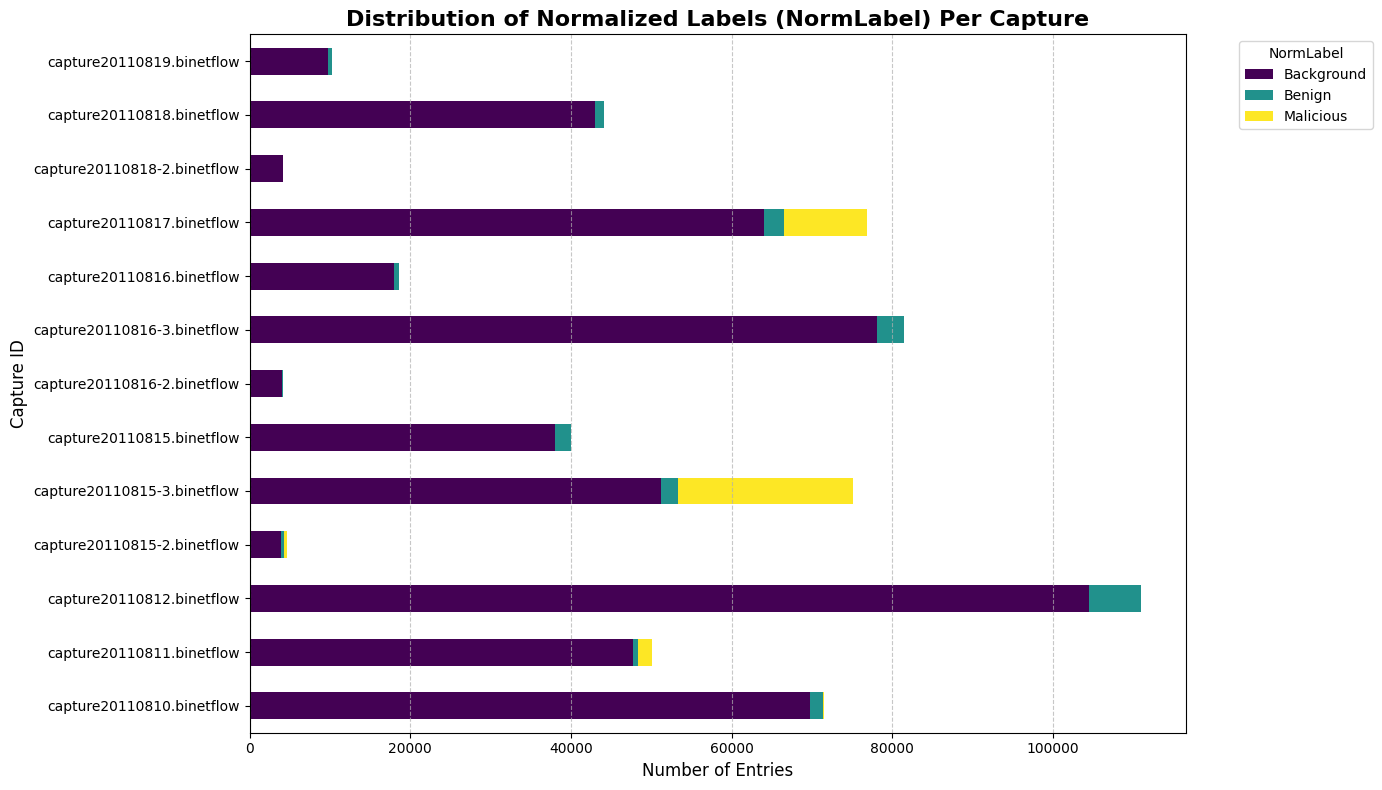

In [ ]:
###############################-Distribution of labels across dataset and captures-########################
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Path to the normalized dataset
normalized_path = '/content/drive/MyDrive/colab_test/unified_captures_filtered_443_rem_lab.csv'

print("Loading normalized dataset...")
# Load only the necessary columns to keep memory footprint low
df_labels = pd.read_csv(normalized_path, usecols=['captureID', 'NormLabel'])

# Calculate overall counts for each NormLabel
overall_counts = df_labels['NormLabel'].value_counts()
total_entries = len(df_labels)

print("\n================ OVERALL LABEL COUNTS ================")
for label, count in overall_counts.items():
    percentage = (count / total_entries) * 100
    print(f"{label:<12}: {count:>10,} ({percentage:.2f}%)")
print(f"Total Entries: {total_entries:,}")
print("======================================================\n")

# Group and count the labels per capture
grouped_counts = df_labels.groupby(['captureID', 'NormLabel']).size().reset_index(name='Count')

# Pivot the data for better plotting alignment
pivot_df = grouped_counts.pivot(index='captureID', columns='NormLabel', values='Count').fillna(0)

# Plotting
fig, ax = plt.subplots(figsize=(14, 8))
pivot_df.plot(kind='barh', stacked=True, ax=ax, colormap='viridis')

plt.title('Distribution of Normalized Labels (NormLabel) Per Capture', fontsize=16, fontweight='bold')
plt.xlabel('Number of Entries', fontsize=12)
plt.ylabel('Capture ID', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.legend(title='NormLabel', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()

# Display the plot
plt.show()

In [ ]:
###############################-Distribution of labels across dataset and captures [table]-########################
import pandas as pd

# Path to the normalized dataset
normalized_path = '/content/drive/MyDrive/colab_test/unified_captures_filtered_443_rem_lab.csv'

print("Loading normalized dataset to generate summary table...")
df_labels = pd.read_csv(normalized_path, usecols=['captureID', 'NormLabel'])

# Aggregate counts by captureID and NormLabel
summary_counts = df_labels.groupby(['captureID', 'NormLabel']).size().unstack(fill_value=0)

# Ensure all expected columns exist even if they are empty in some captures
for col in ['Background', 'Benign', 'Malicious']:
    if col not in summary_counts.columns:
        summary_counts[col] = 0

# Calculate Total flows
summary_counts['Total Flows'] = summary_counts[['Background', 'Benign', 'Malicious']].sum(axis=1)

# Calculate Malicious Percentage
summary_counts['Malicious %'] = (summary_counts['Malicious'] / summary_counts['Total Flows'] * 100).round(4)

# Reorder columns for readability
summary_table = summary_counts[['Total Flows', 'Malicious', 'Benign', 'Background', 'Malicious %']].reset_index()
summary_table.rename(columns={'captureID': 'Capture ID'}, inplace=True)

# Sort by Capture ID
summary_table = summary_table.sort_values(by='Capture ID').reset_index(drop=True)

# Display the resulting table
display(summary_table)

Loading normalized dataset to generate summary table...


NormLabel,Capture ID,Total Flows,Malicious,Benign,Background,Malicious %
0,capture20110810.binetflow,71434,119,1552,69763,0.1666
1,capture20110811.binetflow,50046,1666,645,47735,3.3289
2,capture20110812.binetflow,110931,0,6446,104485,0.0000
3,capture20110815-2.binetflow,4604,347,296,3961,7.5369
4,capture20110815-3.binetflow,75136,21780,2147,51209,28.9874
5,capture20110815.binetflow,39952,0,1966,37986,0.0000
6,capture20110816-2.binetflow,4106,0,89,4017,0.0000
7,capture20110816-3.binetflow,81461,0,3424,78037,0.0000
8,capture20110816.binetflow,18589,0,613,17976,0.0000
9,capture20110817.binetflow,76846,10356,2412,64078,13.4763


In [ ]:
###############################-Captures with actual malicious traffic-########################
# Filter the summary table to find captures with malicious flows > 0
malicious_captures = summary_table[summary_table['Malicious'] > 0]

# Calculate the count of these captures
num_malicious_captures = len(malicious_captures)

# Calculate the total flows for these captures
total_flows_malicious_only = malicious_captures['Total Flows'].sum()

print(f"Number of captures with malicious traffic: {num_malicious_captures}")
print(f"Total flows from only these captures: {total_flows_malicious_only:,}")

# Display the filtered captures
display(malicious_captures)

Number of captures with malicious traffic: 5
Total flows from only these captures: 278,066


NormLabel,Capture ID,Total Flows,Malicious,Benign,Background,Malicious %
0,capture20110810.binetflow,71434,119,1552,69763,0.1666
1,capture20110811.binetflow,50046,1666,645,47735,3.3289
3,capture20110815-2.binetflow,4604,347,296,3961,7.5369
4,capture20110815-3.binetflow,75136,21780,2147,51209,28.9874
9,capture20110817.binetflow,76846,10356,2412,64078,13.4763


In [ ]:
#########################################-Splitting by captures and GroupShuffleSplit-########################################33#
from sklearn.model_selection import GroupShuffleSplit
import pandas as pd

# Load a sample or the full dataset to demonstrate the split
# We will use the GroupShuffleSplit on 'captureID' to keep groups isolated
gss = GroupShuffleSplit(n_splits=1, train_size=0.8, random_state=42)

# Because the dataset is large, we can load it in chunks or load the full dataset if RAM permits
# Here we prepare the split indices based on the capture IDs present in the dataset
unique_captures = summary_table['Capture ID'].unique()
print(f"Unique captures to split: {list(unique_captures)}")

# Define train and test groups
train_idx, test_idx = next(gss.split(X=unique_captures, groups=unique_captures))

train_groups = unique_captures[train_idx]
test_groups = unique_captures[test_idx]

print(f"\nTrain Captures (80% groups): {list(train_groups)}")

print(f"Test Captures (20% groups): {list(test_groups)}")

Unique captures to split: ['capture20110810.binetflow', 'capture20110811.binetflow', 'capture20110812.binetflow', 'capture20110815-2.binetflow', 'capture20110815-3.binetflow', 'capture20110815.binetflow', 'capture20110816-2.binetflow', 'capture20110816-3.binetflow', 'capture20110816.binetflow', 'capture20110817.binetflow', 'capture20110818-2.binetflow', 'capture20110818.binetflow', 'capture20110819.binetflow']

Train Captures (80% groups): ['capture20110811.binetflow', 'capture20110812.binetflow', 'capture20110815-2.binetflow', 'capture20110815-3.binetflow', 'capture20110815.binetflow', 'capture20110816-2.binetflow', 'capture20110816-3.binetflow', 'capture20110816.binetflow', 'capture20110818-2.binetflow', 'capture20110819.binetflow']
Test Captures (20% groups): ['capture20110810.binetflow', 'capture20110817.binetflow', 'capture20110818.binetflow']


In [ ]:
##################################-Actual split percentages-################################3333
# Calculate and verify the flow distributions under this split
train_flows = summary_table[summary_table['Capture ID'].isin(train_groups)]
test_flows = summary_table[summary_table['Capture ID'].isin(test_groups)]

total_train = train_flows['Total Flows'].sum()
total_test = test_flows['Total Flows'].sum()
actual_ratio = total_train / (total_train + total_test) * 100

print(f"Total Train Flows: {total_train:,} ({actual_ratio:.2f}%)")
print(f"Total Test Flows: {total_test:,} ({100 - actual_ratio:.2f}%)")

Total Train Flows: 399,218 (67.47%)
Total Test Flows: 192,440 (32.53%)


Loading dataset to map train/test distributions...

--- Raw Flow Counts per Split ---


NormLabel,Background,Benign,Malicious
Split,,,
Test,176770,5195,10475
Train,359289,16136,23793



--- Label Percentages per Split ---


NormLabel,Background,Benign,Malicious
Split,,,
Test,91.86,2.70,5.44
Train,90.00,4.04,5.96


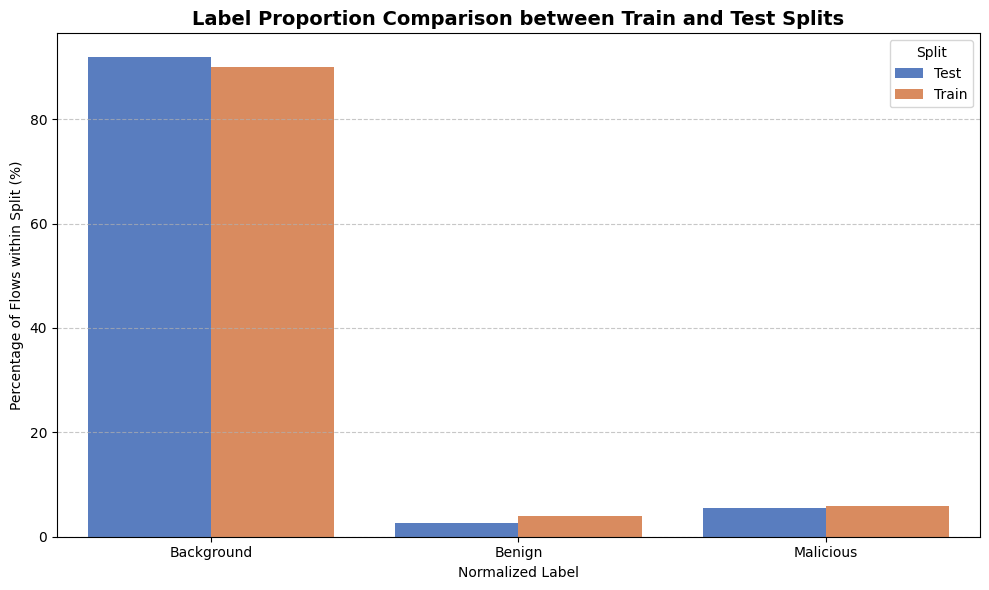

In [ ]:
################################-Label distribution across training and testing splits-#######################################33
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the full labels dataset with the capture IDs
print("Loading dataset to map train/test distributions...")
df_all = pd.read_csv(normalized_path, usecols=['captureID', 'NormLabel'])

# Map each flow to either train or test based on its captureID
train_set_names = set(train_groups)
df_all['Split'] = df_all['captureID'].apply(lambda x: 'Train' if x in train_set_names else 'Test')

# Calculate counts
split_counts = df_all.groupby(['Split', 'NormLabel']).size().unstack(fill_value=0)

# Calculate percentages within each split
split_percentages = split_counts.div(split_counts.sum(axis=1), axis=0) * 100

print("\n--- Raw Flow Counts per Split ---")
display(split_counts)

print("\n--- Label Percentages per Split ---")
display(split_percentages.round(2))

# Reshape for easier plotting with seaborn
plot_data = split_percentages.reset_index().melt(id_vars='Split', value_name='Percentage', var_name='NormLabel')

# Plot side-by-side comparison of label distributions
plt.figure(figsize=(10, 6))
sns.barplot(data=plot_data, x='NormLabel', y='Percentage', hue='Split', palette='muted')
plt.title('Label Proportion Comparison between Train and Test Splits', fontsize=14, fontweight='bold')
plt.ylabel('Percentage of Flows within Split (%)')
plt.xlabel('Normalized Label')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [ ]:
###############################-Creation of the splits-#################################
import os
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit

# Base paths
base_dir = '/content/drive/MyDrive/colab_test'
input_file = os.path.join(base_dir, 'unified_captures_filtered_443_rem_lab.csv')
train_output_file = os.path.join(base_dir, 'unified_captures_train.csv')
test_output_file = os.path.join(base_dir, 'unified_captures_test.csv')

print("Loading dataset...")
df = pd.read_csv(input_file)

# Identify unique capture groups
unique_captures = df['captureID'].unique()
print(f"Unique captures found: {list(unique_captures)}")

# Create 80/20 group split based on captureID
gss = GroupShuffleSplit(n_splits=1, train_size=0.8, random_state=42)
train_idx, test_idx = next(gss.split(X=unique_captures, groups=unique_captures))

train_groups = set(unique_captures[train_idx])
test_groups = set(unique_captures[test_idx])

print(f"\nTrain Captures: {list(train_groups)}")
print(f"Test Captures: {list(test_groups)}")

# Segment the DataFrame
print("\nSegmenting data into train and test splits...")
df_train = df[df['captureID'].isin(train_groups)]
df_test = df[df['captureID'].isin(test_groups)]

# Save to new CSV files
print(f"Saving training split to: {train_output_file}")
df_train.to_csv(train_output_file, index=False)

print(f"Saving testing split to: {test_output_file}")
df_test.to_csv(test_output_file, index=False)

print("\nSplits successfully created and saved!")
print(f"Train Rows: {len(df_train):,}")
print(f"Test Rows: {len(df_test):,}")

Loading dataset...
Unique captures found: ['capture20110810.binetflow', 'capture20110811.binetflow', 'capture20110812.binetflow', 'capture20110815-2.binetflow', 'capture20110815-3.binetflow', 'capture20110815.binetflow', 'capture20110816-2.binetflow', 'capture20110816-3.binetflow', 'capture20110816.binetflow', 'capture20110817.binetflow', 'capture20110818-2.binetflow', 'capture20110818.binetflow', 'capture20110819.binetflow']

Train Captures: ['capture20110819.binetflow', 'capture20110815-3.binetflow', 'capture20110815.binetflow', 'capture20110811.binetflow', 'capture20110812.binetflow', 'capture20110818-2.binetflow', 'capture20110815-2.binetflow', 'capture20110816-3.binetflow', 'capture20110816-2.binetflow', 'capture20110816.binetflow']
Test Captures: ['capture20110810.binetflow', 'capture20110818.binetflow', 'capture20110817.binetflow']

Segmenting data into train and test splits...
Saving training split to: /content/drive/MyDrive/colab_test/unified_captures_train.csv
Saving testing 

In [ ]:
##################################-Skewness of TotPkts, TotBytes and SrcBytes-#############################
import pandas as pd
import numpy as np

# Define paths based on previous cell variables
train_path = '/content/drive/MyDrive/colab_test/unified_captures_train.csv'
test_path = '/content/drive/MyDrive/colab_test/unified_captures_test.csv'

print("Loading datasets...")
df_train = pd.read_csv(train_path)
df_test = pd.read_csv(test_path)

target_cols = ['TotPkts', 'TotBytes', 'SrcBytes']

# Check skewness
print("=== Skewness (Asymmetry) Before Transformation ===")
for col in target_cols:
    train_skew = df_train[col].skew()
    test_skew = df_test[col].skew()
    print(f"{col:<10} | Train Skew: {train_skew:>10.4f} | Test Skew: {test_skew:>10.4f}")

Loading datasets...
=== Skewness (Asymmetry) Before Transformation ===
TotPkts    | Train Skew:   141.5800 | Test Skew:   390.1303
TotBytes   | Train Skew:   137.4119 | Test Skew:   412.5579
SrcBytes   | Train Skew:   246.2915 | Test Skew:   138.9652


In [ ]:
##################################-Log transformation of TotPkts, TotBytes and SrcBytes-#############################
# Apply log transformation using log1p to avoid errors with 0 values
print("\nApplying log1p transformation to both splits...")
for col in target_cols:
    df_train[col] = np.log1p(df_train[col])
    df_test[col] = np.log1p(df_test[col])

# Check skewness after transformation
print("=== Skewness (Asymmetry) After Transformation ===")
for col in target_cols:
    train_skew = df_train[col].skew()
    test_skew = df_test[col].skew()
    print(f"{col:<10} | Train Skew: {train_skew:>10.4f} | Test Skew: {test_skew:>10.4f}")

# Overwrite the files with transformed features
df_train.to_csv(train_path, index=False)
df_test.to_csv(test_path, index=False)
print("\nTransformed datasets saved successfully to Google Drive!")


Applying log1p transformation to both splits...
=== Skewness (Asymmetry) After Transformation ===
TotPkts    | Train Skew:     1.1487 | Test Skew:     0.7947
TotBytes   | Train Skew:     0.4502 | Test Skew:     0.2062
SrcBytes   | Train Skew:     0.1577 | Test Skew:     0.1280

Transformed datasets saved successfully to Google Drive!


In [ ]:
##################################-Skewness of Dur-#############################
import pandas as pd
import numpy as np

train_path = '/content/drive/MyDrive/colab_test/unified_captures_train.csv'
test_path = '/content/drive/MyDrive/colab_test/unified_captures_test.csv'

print("Loading datasets...")
df_train = pd.read_csv(train_path)
df_test = pd.read_csv(test_path)

# Check initial skewness for the 'Dur' column
print("=== Skewness (Asymmetry) of 'Dur' Before Transformation ===")
train_skew = df_train['Dur'].skew()
test_skew = df_test['Dur'].skew()
print(f"Dur | Train Skew: {train_skew:>10.4f} | Test Skew: {test_skew:>10.4f}")

Loading datasets...
=== Skewness (Asymmetry) of 'Dur' Before Transformation ===
Dur | Train Skew:     6.6018 | Test Skew:     5.6443


In [ ]:
##################################-Log trasformation of Dur-#############################
# Apply log transformation using log1p
print("\nApplying log1p transformation to 'Dur'...")
df_train['Dur'] = np.log1p(df_train['Dur'])
df_test['Dur'] = np.log1p(df_test['Dur'])

# Verify skewness after transformation
print("=== Skewness (Asymmetry) of 'Dur' After Transformation ===")
train_skew_after = df_train['Dur'].skew()
test_skew_after = df_test['Dur'].skew()
print(f"Dur | Train Skew: {train_skew_after:>10.4f} | Test Skew: {test_skew_after:>10.4f}")

# Overwrite the files with transformed Dur feature
df_train.to_csv(train_path, index=False)
df_test.to_csv(test_path, index=False)
print("\nDatasets with transformed 'Dur' saved successfully to Google Drive!")


Applying log1p transformation to 'Dur'...
=== Skewness (Asymmetry) of 'Dur' After Transformation ===
Dur | Train Skew:     0.8553 | Test Skew:     0.7282

Datasets with transformed 'Dur' saved successfully to Google Drive!


In [ ]:
#################################-Distribution of State-####################################
# Check the unique values and distribution of the 'State' column
print("=== Unique States in Train Split ===")
train_state_counts = df_train['State'].value_counts(dropna=False)
print(f"Total unique states in Train: {len(train_state_counts)}")
print(train_state_counts.head(15))

print("\n=== Unique States in Test Split ===")
test_state_counts = df_test['State'].value_counts(dropna=False)
print(f"Total unique states in Test: {len(test_state_counts)}")
print(test_state_counts.head(15))

=== Unique States in Train Split ===
Total unique states in Train: 222
State
FSPA_FSPA     132199
CON            87759
FSRPA_FSPA     46505
SRPA_FSPA      25761
S_RA           24339
SRPA_SPA       14265
S_SA           11386
S_              7987
PA_PA           4616
FSPA_FSRPA      4531
SR_SA           4309
SPA_SPA         3475
INT             2829
SPA_FSPA        2734
FSRPA_SPA       2595
Name: count, dtype: int64

=== Unique States in Test Split ===
Total unique states in Test: 237
State
FSPA_FSPA     68379
CON           48696
FSRPA_FSPA    13795
SRPA_FSPA     12286
S_RA           7692
SRPA_SPA       6294
S_SA           5610
S_             3314
PA_PA          2908
FSPA_FSRPA     2534
SR_SA          2037
SPA_SPA        1991
INT            1968
FSRPA_SPA      1592
SPA_FSPA       1466
Name: count, dtype: int64


In [ ]:
##############################-One hot encoding in State-###################################
import pandas as pd

train_path = '/content/drive/MyDrive/colab_test/unified_captures_train.csv'
test_path = '/content/drive/MyDrive/colab_test/unified_captures_test.csv'

print("Loading datasets...")
df_train = pd.read_csv(train_path)
df_test = pd.read_csv(test_path)

# Identify top 15 states in the training split
top_15_states = df_train['State'].value_counts().head(15).index.tolist()
print(f"Top 15 States to keep: {top_15_states}")

# Map states outside top 15 to 'Other'
df_train['State_Grouped'] = df_train['State'].apply(lambda x: x if x in top_15_states else 'Other')
df_test['State_Grouped'] = df_test['State'].apply(lambda x: x if x in top_15_states else 'Other')

# Perform One-Hot Encoding
df_train_encoded = pd.get_dummies(df_train['State_Grouped'], prefix='State', dtype=int)
df_test_encoded = pd.get_dummies(df_test['State_Grouped'], prefix='State', dtype=int)

# Align columns so that both splits have exactly the same one-hot encoded features
# (e.g., in case 'Other' or any state is missing in one split, though rare)
expected_columns = [f'State_{state}' for state in top_15_states] + ['State_Other']
for col in expected_columns:
    if col not in df_train_encoded.columns:
        df_train_encoded[col] = 0
    if col not in df_test_encoded.columns:
        df_test_encoded[col] = 0

df_train_encoded = df_train_encoded[expected_columns]
df_test_encoded = df_test_encoded[expected_columns]

# Concatenate back to the original DataFrames and drop old State columns
df_train = pd.concat([df_train.drop(columns=['State', 'State_Grouped']), df_train_encoded], axis=1)
df_test = pd.concat([df_test.drop(columns=['State', 'State_Grouped']), df_test_encoded], axis=1)

print(f"One-Hot Encoding completed! New columns added: {len(expected_columns)}")
print(f"Training columns shape: {df_train.shape}")
print(f"Testing columns shape: {df_test.shape}")

Loading datasets...
Top 15 States to keep: ['FSPA_FSPA', 'CON', 'FSRPA_FSPA', 'SRPA_FSPA', 'S_RA', 'SRPA_SPA', 'S_SA', 'S_', 'PA_PA', 'FSPA_FSRPA', 'SR_SA', 'SPA_SPA', 'INT', 'SPA_FSPA', 'FSRPA_SPA']
One-Hot Encoding completed! New columns added: 16
Training columns shape: (399218, 29)
Testing columns shape: (192440, 29)


In [ ]:
# Save the datasets back to Google Drive
print("Saving updated datasets with encoded states to Google Drive...")
df_train.to_csv(train_path, index=False)
df_test.to_csv(test_path, index=False)
print("Datasets successfully updated and saved!")
display(df_train.head(3))

Saving updated datasets with encoded states to Google Drive...
Datasets successfully updated and saved!


,StartTime,Dur,Proto,SrcAddr,Sport,DstAddr,Dport,TotPkts,TotBytes,SrcBytes,...,State_S_SA,State_S_,State_PA_PA,State_FSPA_FSRPA,State_SR_SA,State_SPA_SPA,State_INT,State_SPA_FSPA,State_FSRPA_SPA,State_Other
0,2011/08/11 09:49:35.723936,8.164130,tcp,147.32.84.229,443.0,155.56.68.217,60992,7.210080,11.876693,11.070381,...,0,0,1,0,0,0,0,0,0,0
1,2011/08/11 09:49:35.742878,8.184197,tcp,147.32.84.229,443.0,212.103.28.2,41132,6.929517,11.480960,10.608366,...,0,0,1,0,0,0,0,0,0,0
2,2011/08/11 09:49:35.744137,7.262929,tcp,147.32.84.229,443.0,80.13.58.179,58297,5.407172,9.768298,8.965207,...,0,0,0,0,0,0,0,0,0,1


In [ ]:
#########################-Apply an Standar Scaling to the dataset splits-#############################
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler

train_path = '/content/drive/MyDrive/colab_test/unified_captures_train.csv'
test_path = '/content/drive/MyDrive/colab_test/unified_captures_test.csv'

print("Loading datasets for scaling...")
df_train = pd.read_csv(train_path)
df_test = pd.read_csv(test_path)

# Identify numerical columns to scale
num_cols = ['Dur', 'TotPkts', 'TotBytes', 'SrcBytes']
print(f"Numerical columns to scale: {num_cols}")

# Initialize StandardScaler
scaler = StandardScaler()

# Fit on training data and transform both
print("Fitting scaler on Train set and transforming both splits...")
df_train[num_cols] = scaler.fit_transform(df_train[num_cols])
df_test[num_cols] = scaler.transform(df_test[num_cols])

# Quick statistical preview of scaled features
print("\n=== Train Scaled Stats ===")
display(df_train[num_cols].describe())

print("=== Test Scaled Stats ===")
display(df_test[num_cols].describe())

# Save the final scaled datasets back to Google Drive
print("Saving scaled datasets back to Google Drive...")
df_train.to_csv(train_path, index=False)
df_test.to_csv(test_path, index=False)
print("Datasets successfully scaled and saved!")

Loading datasets for scaling...
Numerical columns to scale: ['Dur', 'TotPkts', 'TotBytes', 'SrcBytes']
Fitting scaler on Train set and transforming both splits...

=== Train Scaled Stats ===


,Dur,TotPkts,TotBytes,SrcBytes
count,3.992180e+05,3.992180e+05,3.992180e+05,3.992180e+05
mean,7.233255e-17,5.467657e-17,2.990125e-16,9.112762e-18
std,1.000001e+00,1.000001e+00,1.000001e+00,1.000001e+00
min,-9.655337e-01,-1.526197e+00,-1.604972e+00,-3.617037e+00
25%,-9.117091e-01,-8.246074e-01,-9.606737e-01,-9.187081e-01
50%,-3.621579e-01,1.124186e-01,1.475679e-01,2.652715e-01
75%,7.705237e-01,4.944884e-01,6.699080e-01,6.556763e-01
max,2.882601e+00,8.515121e+00,6.080338e+00,6.692580e+00


=== Test Scaled Stats ===


,Dur,TotPkts,TotBytes,SrcBytes
count,192440.000000,192440.000000,192440.000000,192440.000000
mean,0.061127,-0.059140,-0.047149,-0.009744
std,1.058320,0.978792,0.984822,1.039666
min,-0.965534,-1.526197,-1.604972,-3.617037
25%,-0.964446,-1.215739,-1.257917,-1.348796
50%,-0.292848,0.112419,0.199255,0.285754
75%,0.951614,0.466642,0.630254,0.717600
max,2.882601,8.750877,6.238557,5.908567


Saving scaled datasets back to Google Drive...
Datasets successfully scaled and saved!


In [ ]:
#####################-Converting StartTime type into datetime-###################################
# Convert StartTime string to datetime objects
train_df['StartTime_dt'] = pd.to_datetime(train_df['StartTime'])
test_df['StartTime_dt'] = pd.to_datetime(test_df['StartTime'])

# Sort datasets chronologically to preserve sequence integrity for the LSTM
train_df = train_df.sort_values(by='StartTime_dt').reset_index(drop=True)
test_df = test_df.sort_values(by='StartTime_dt').reset_index(drop=True)

# Calculate TimeDiff (time elapsed since the previous flow) in seconds
train_df['TimeDiff'] = train_df['StartTime_dt'].diff().dt.total_seconds().fillna(0.0)
test_df['TimeDiff'] = test_df['StartTime_dt'].diff().dt.total_seconds().fillna(0.0)

# Verify the chronological sorting and new features without including other columns
display(train_df[['StartTime_dt', 'TimeDiff', 'Dur', 'TotPkts']].head(10))

,StartTime_dt,TimeDiff,Dur,TotPkts
0,2011-08-11 09:49:35.723936,0.000000,2.870930,3.463718
1,2011-08-11 09:49:35.742878,0.018942,2.880359,3.248895
2,2011-08-11 09:49:35.744137,0.001259,2.447440,2.083259
3,2011-08-11 09:49:35.770036,0.025899,2.881612,3.985055
4,2011-08-11 09:49:35.770053,0.000017,1.184490,-0.685007
5,2011-08-11 09:49:35.790892,0.020839,-0.965132,-1.215739
6,2011-08-11 09:49:35.830980,0.040088,2.517864,0.521357
7,2011-08-11 09:49:35.850580,0.019600,2.881154,3.604920
8,2011-08-11 09:49:35.902966,0.052386,2.880152,3.160020
9,2011-08-11 09:49:35.903467,0.000501,1.929576,1.940217
